In [1]:
import os, json, glob
import numpy as np
import matplotlib.pyplot as plt
from config import PREPROCESSED, FIGURES, print_versions
print_versions()

P05  = str(PREPROCESSED)
ROOT = os.path.dirname(os.path.dirname(P05))
FIG = str(FIGURES)
FS = 125
CACHE = os.path.join(P05, "cache")
os.makedirs(CACHE, exist_ok=True)
RECOMPUTE = False          # set True to force a rerun of cached results

VOWELS = {"AA","AE","AH","AO","AW","AY","EH","ER","EY",
          "IH","IY","OW","OY","UH","UW"}
SILENCE = {"", "sil", "sp", "spn"}

ch_names = open(os.path.join(P05, "ch_names.txt")).read().split()
chapters = [os.path.splitext(os.path.basename(w))[0]
            for w in sorted(glob.glob(os.path.join(ROOT, "audiobooks", "*.wav")))]

onsets, vow_on, con_on, str_on, uns_on, lengths = [], [], [], [], [], []
for i, ch in enumerate(chapters):
    n = np.load(os.path.join(P05, f"stim_part{i:02d}.npy")).shape[0]
    lengths.append(n)

    with open(os.path.join(ROOT, "audiobooks", f"{ch}_annotations.json")) as f:
        ph = json.load(f)["phones"]

    o = np.zeros(n); v = np.zeros(n); c = np.zeros(n)
    s = np.zeros(n); u = np.zeros(n)
    for p in ph:
        lab = p["label"].strip()
        if lab in SILENCE:
            continue
        k = int(round(p["start"] * FS))
        if not (0 <= k < n):
            continue
        o[k] = 1
        base = lab.rstrip("012")
        if base in VOWELS:
            v[k] = 1
            (s if lab[-1] == "1" else u)[k] = 1
        else:
            c[k] = 1

    onsets.append(o); vow_on.append(v); con_on.append(c)
    str_on.append(s); uns_on.append(u)

total_dur = sum(lengths) / FS
n_all = int(sum(o.sum() for o in onsets))
n_vow = int(sum(v.sum() for v in vow_on))
n_con = int(sum(c.sum() for c in con_on))
n_str = int(sum(s.sum() for s in str_on))
n_uns = int(sum(u.sum() for u in uns_on))

print(f"all phones  {n_all:6d}   {n_all/total_dur:5.2f} per s")
print(f"vowels      {n_vow:6d}   {n_vow/total_dur:5.2f} per s")
print(f"consonants  {n_con:6d}   {n_con/total_dur:5.2f} per s")
print(f"  stressed  {n_str:6d}   {n_str/total_dur:5.2f} per s")
print(f"  unstressed{n_uns:6d}   {n_uns/total_dur:5.2f} per s")
print(f"checks: vow+con == all  {n_vow + n_con == n_all};  "
      f"str+uns == vow  {n_str + n_uns == n_vow}")

Python 3.12.13 | numpy 2.5.3 | scipy 1.18.1 | sklearn 1.9.0 | mne 1.12.1 | h5py 3.16.0 | matplotlib 3.11.1
all phones   22327    9.37 per s
vowels        8875    3.73 per s
consonants   13452    5.65 per s
  stressed    5142    2.16 per s
  unstressed  3733    1.57 per s
checks: vow+con == all  True;  str+uns == vow  True


n stressed 5142   n unstressed 3733

duration   stressed  117.9 ms   unstressed   66.6 ms   d' +0.84
peak env   stressed 4211.597      unstressed 3473.155      d' +0.44

unstressed duration percentiles [ms] [30. 30. 30.]
  minimum 30.0 ms, held by 0.278 of tokens


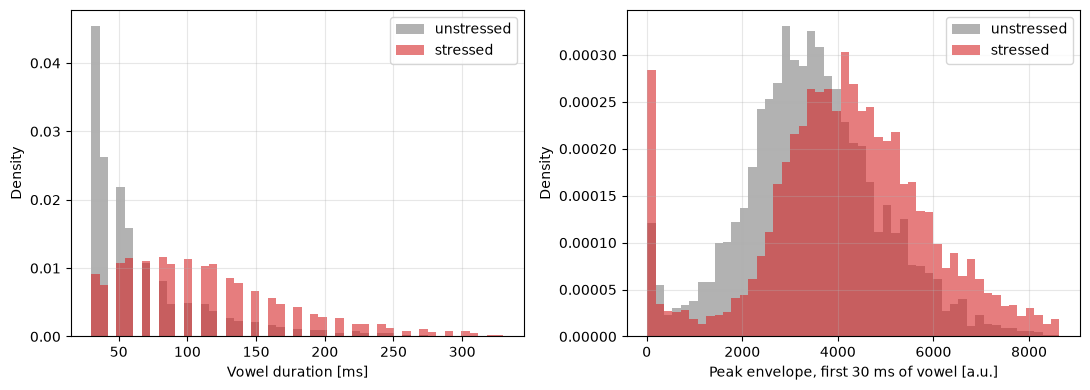

In [2]:
from scipy.stats import zscore

def dprime(a, b):
    sd = np.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)
    return (a.mean() - b.mean()) / sd

W = int(round(0.030 * FS))

dur_s, dur_u, amp_s, amp_u = [], [], [], []

for i, ch in enumerate(chapters):
    env = np.load(os.path.join(P05, f"stim_part{i:02d}.npy"))
    n = env.shape[0]

    with open(os.path.join(ROOT, "audiobooks", f"{ch}_annotations.json")) as f:
        ph = json.load(f)["phones"]

    for j, p in enumerate(ph):
        lab = p["label"].strip()
        if lab in SILENCE or lab.rstrip("012") not in VOWELS:
            continue
        k0 = int(round(p["start"] * FS))
        end = p.get("end", ph[j+1]["start"] if j+1 < len(ph) else p["start"])
        k1 = int(round(end * FS))
        if not (0 <= k0 < k1 <= n) or k0 + W > n:
            continue

        d = end - p["start"]
        a = env[k0:k0 + W].max()
        if lab[-1] == "1":
            dur_s.append(d); amp_s.append(a)
        else:
            dur_u.append(d); amp_u.append(a)

dur_s, dur_u = np.array(dur_s), np.array(dur_u)
amp_s, amp_u = np.array(amp_s), np.array(amp_u)

print(f"n stressed {len(dur_s)}   n unstressed {len(dur_u)}\n")
print(f"duration   stressed {dur_s.mean()*1000:6.1f} ms   "
      f"unstressed {dur_u.mean()*1000:6.1f} ms   d' {dprime(dur_s, dur_u):+.2f}")
print(f"peak env   stressed {amp_s.mean():6.3f}      "
      f"unstressed {amp_u.mean():6.3f}      d' {dprime(amp_s, amp_u):+.2f}")

# durations at the aligner's 30 ms floor
mn = np.round(dur_u.min()*1000, 1)
print(f"\nunstressed duration percentiles [ms] {np.percentile(dur_u*1000, [1, 5, 10]).round(1)}")
print(f"  minimum {mn} ms, held by {(np.round(dur_u*1000, 1) == mn).mean():.3f} of tokens")

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, (s, u, name, unit) in zip(
        axs, [(dur_s*1000, dur_u*1000, 'Vowel duration', 'ms'),
              (amp_s, amp_u, 'Peak envelope, first 30 ms of vowel', 'a.u.')]):
    lo, hi = np.percentile(np.concatenate([s, u]), [0, 99])
    bins = np.linspace(lo, hi, 50)
    ax.hist(u, bins=bins, alpha=0.6, label='unstressed', color='tab:grey', density=True)
    ax.hist(s, bins=bins, alpha=0.6, label='stressed',   color='tab:red',  density=True)
    ax.set_xlabel(f'{name} [{unit}]'); ax.set_ylabel('Density')
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIG, "ph_stress_validation.pdf"), bbox_inches="tight")

next-onset interval [ms]
  stressed    median  100.0   mean  125.8   n 5141
  unstressed  median   50.0   mean   86.1   n 3731
  d' +0.29
  fraction with next onset inside 350 ms   stressed 0.981   unstressed 0.968


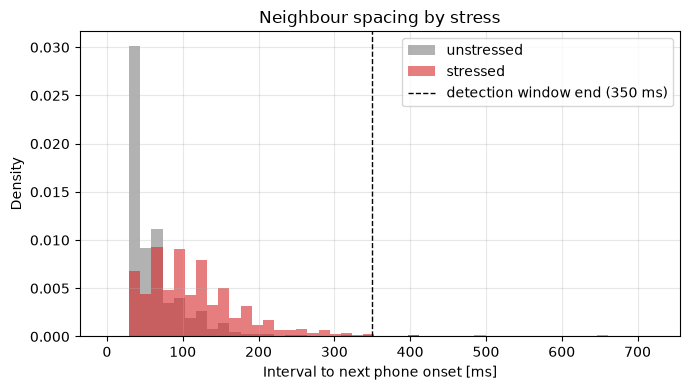

In [3]:
WIN_END = 350
gap_s, gap_u = [], []


for i, ch in enumerate(chapters):
    n = lengths[i]
    with open(os.path.join(ROOT, "audiobooks", f"{ch}_annotations.json")) as f:
        ph = json.load(f)["phones"]

    # onsets of every non-silence phone, in order
    ons = [(p["start"], p["label"].strip()) for p in ph
           if p["label"].strip() not in SILENCE]

    for j, (t, lab) in enumerate(ons):
        if lab.rstrip("012") not in VOWELS or j + 1 >= len(ons):
            continue
        k = int(round(t * FS))
        if not (0 <= k < n):
            continue
        g = ons[j+1][0] - t
        (gap_s if lab[-1] == "1" else gap_u).append(g)

gap_s, gap_u = np.array(gap_s) * 1000, np.array(gap_u) * 1000

print(f"next-onset interval [ms]")
print(f"  stressed    median {np.median(gap_s):6.1f}   mean {gap_s.mean():6.1f}   "
      f"n {len(gap_s)}")
print(f"  unstressed  median {np.median(gap_u):6.1f}   mean {gap_u.mean():6.1f}   "
      f"n {len(gap_u)}")
print(f"  d' {dprime(gap_s, gap_u):+.2f}")
print(f"  fraction with next onset inside {WIN_END} ms   "
      f"stressed {(gap_s < WIN_END).mean():.3f}   unstressed {(gap_u < WIN_END).mean():.3f}")


plt.figure(figsize=(7, 4))
bins = np.linspace(0, np.percentile(np.concatenate([gap_s, gap_u]), 99), 50)
plt.hist(gap_u, bins=bins, alpha=0.6, density=True, color='tab:grey', label='unstressed')
plt.hist(gap_s, bins=bins, alpha=0.6, density=True, color='tab:red',  label='stressed')
plt.axvline(WIN_END, c='k', ls='--', lw=1, label=f'detection window end ({WIN_END} ms)')
plt.xlabel('Interval to next phone onset [ms]'); plt.ylabel('Density')
plt.title('Neighbour spacing by stress'); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIG, "ph_spacing.pdf"), bbox_inches="tight")

phone onset  test mean r 0.0205   max r 0.1051   best FC5
    FC5  0.1051
    FC3  0.1005
    FCz  0.0630
    FT7  0.0526
    FC1  0.0511


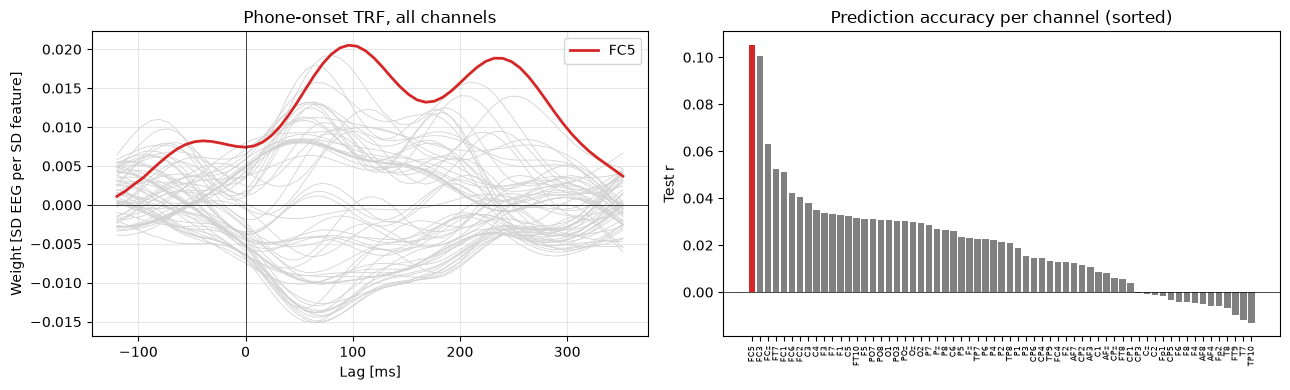

In [4]:
from scipy.stats import pearsonr

def lagged_matrix(X, lags):
    """Lagged copies of X (features x time) for one chapter, edge samples discarded."""
    n = X.shape[1]
    t0, t1 = lags.max(), n + lags.min()          # samples with every lag available
    return np.vstack([X[:, t0 - L : t1 - L] for L in lags])

def trim(eeg, lags):
    """The EEG samples that line up with lagged_matrix."""
    return eeg[:, lags.max() : eeg.shape[1] + lags.min()]

lags = np.arange(-20, 50)          # -160 to 392 ms
ridge_parameter = 1e3
train_parts, val_parts, test_parts = range(9), range(9, 12), range(12, 15)

eegs, phs = [], []
for i in range(15):
    e = np.load(os.path.join(P05, f"eeg_part{i:02d}.npy"))
    n = min(e.shape[1], lengths[i])
    eegs.append(zscore(e[:, :n], axis=1))
    phs.append(zscore(onsets[i][:n]))

tr_eeg = np.hstack([trim(eegs[i], lags) for i in train_parts])
va_eeg = np.hstack([trim(eegs[i], lags) for i in val_parts])
te_eeg = np.hstack([trim(eegs[i], lags) for i in test_parts])

Xtr = np.hstack([lagged_matrix(phs[i][None, :], lags) for i in train_parts])
Xte = np.hstack([lagged_matrix(phs[i][None, :], lags) for i in test_parts])

coef = np.linalg.inv(Xtr @ Xtr.T
                     + ridge_parameter * np.eye(Xtr.shape[0])) @ Xtr @ tr_eeg.T
pred = Xte.T @ coef

r = np.array([pearsonr(pred[:, c], te_eeg[c])[0] for c in range(63)])
print(f"phone onset  test mean r {r.mean():.4f}   max r {r.max():.4f}   best {ch_names[r.argmax()]}")
for c in np.argsort(r)[::-1][:5]:
    print(f"  {ch_names[c]:>5}  {r[c]:.4f}")

t_ms = lags / FS * 1000
keep = slice(5, len(lags) - 5)        # drop the unstable end lags
c = ch_names.index('FC5') # best channel on the validation chapters (next cell)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))

ax[0].plot(t_ms[keep], coef[keep], c='lightgrey', lw=0.6)
ax[0].plot(t_ms[keep], coef[keep, c], c='tab:red', lw=2, label='FC5')
ax[0].axhline(0, c='k', lw=0.5); ax[0].axvline(0, c='k', lw=0.5)
ax[0].set_xlabel('Lag [ms]'); ax[0].set_ylabel('Weight [SD EEG per SD feature]')
ax[0].set_title('Phone-onset TRF, all channels')
ax[0].legend(); ax[0].grid(alpha=0.3)

order = np.argsort(r)[::-1]
ax[1].bar(range(63), r[order],
          color=['tab:red' if k == c else 'grey' for k in order])
ax[1].set_xticks(range(63))
ax[1].set_xticklabels([ch_names[k] for k in order], rotation=90, fontsize=6)
ax[1].axhline(0, c='k', lw=0.5)
ax[1].set_ylabel('Test r'); ax[1].set_title('Prediction accuracy per channel (sorted)')

plt.tight_layout()
plt.savefig(os.path.join(FIG, "ph_trf.pdf"), bbox_inches="tight")

In [5]:
# channel chosen on the validation chapters, and TRF peaks at that channel ---
from scipy.signal import find_peaks

Xva = np.hstack([lagged_matrix(phs[i][None, :], lags) for i in val_parts])
pv = Xva.T @ coef
r_val = np.array([pearsonr(pv[:, k], va_eeg[k])[0] for k in range(63)])
best = r_val.argmax()
print(f"best on validation: {ch_names[best]} (val r {r_val[best]:.4f}, test r {r[best]:.4f})")
print(f"test mean r {r.mean():.4f}\n")

w, tk = coef[keep, best], t_ms[keep]
for p in find_peaks(w)[0]:  print(f"peak   {tk[p]:4.0f} ms   weight {w[p]:.4f}")
for p in find_peaks(-w)[0]: print(f"trough {tk[p]:4.0f} ms   weight {w[p]:.4f}")
print(f"negative lags: mean {w[tk < 0].mean():.4f}   min {w[tk < 0].min():.4f}   max {w[tk < 0].max():.4f}")

best on validation: FC5 (val r 0.1455, test r 0.1051)
test mean r 0.0205

peak    -40 ms   weight 0.0082
peak     96 ms   weight 0.0205
peak    232 ms   weight 0.0189
trough    0 ms   weight 0.0074
trough  168 ms   weight 0.0132
negative lags: mean 0.0059   min 0.0011   max 0.0082


In [6]:
# circular-shift null and corrected threshold ---
lens = [len(phs[i]) + lags.min() - lags.max() for i in test_parts]
bounds = np.cumsum([0] + lens)
rng = np.random.default_rng(0)
N_NULL = 1000
pz = zscore(pred, axis=0)
null_r = np.empty((N_NULL, 63))
for j in range(N_NULL):
    shifted = np.hstack([np.roll(te_eeg[:, i0:i1], rng.integers(10*FS, (i1 - i0) - 10*FS), axis=1)
                         for i0, i1 in zip(bounds[:-1], bounds[1:])])
    null_r[j] = (pz * zscore(shifted, axis=1).T).mean(axis=0)

for name, obs, null in [(ch_names[best], r[best], null_r[:, best]),
                        ("mean", r.mean(), null_r.mean(axis=1))]:
    p = ((null >= obs).sum() + 1) / (N_NULL + 1)
    print(f"{name:>5}  observed {obs:.4f}   null mean {null.mean():.4f}   "
          f"95th {np.percentile(null, 95):.4f}   p = {p:.4f}")

thr = np.percentile(null_r.max(axis=1), 95)
sig = r > thr
print(f"\ncorrected threshold {thr:.4f}: " + ", ".join(f"{ch_names[k]} {r[k]:.4f}" for k in np.flatnonzero(sig)))

  FC5  observed 0.1051   null mean 0.0001   95th 0.0379   p = 0.0010
 mean  observed 0.0205   null mean -0.0001   95th 0.0170   p = 0.0310

corrected threshold 0.0586: FC3 0.1005, FC5 0.1051, FCz 0.0630


96 ms   most positive ['FC5', 'FC3', 'FC6', 'FC4', 'FT7']   most negative ['O1', 'PO7', 'Oz', 'TP10', 'PO3']
232 ms   most positive ['FC5', 'FC3', 'FT7', 'FC1', 'C5']   most negative ['PO7', 'P7', 'O1', 'PO3', 'POz']


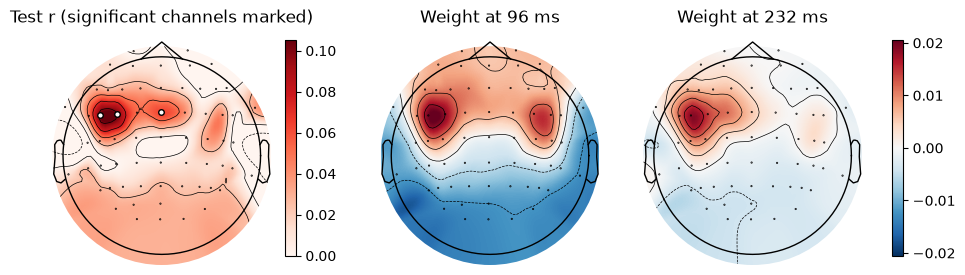

In [7]:
# scalp maps of accuracy and TRF weights at the two largest peaks ---
import mne

info = mne.create_info(ch_names, FS, ch_types='eeg')
info.set_montage('standard_1005')
pk = find_peaks(w)[0]
ks = sorted(pk[np.argsort(w[pk])[::-1][:2]] + keep.start)
v = np.abs(coef[ks, :]).max()

fig, axs = plt.subplots(1, 1 + len(ks), figsize=(4 * (1 + len(ks)), 4))
im0, _ = mne.viz.plot_topomap(r, info, axes=axs[0], cmap='Reds', vlim=(0, r.max()), mask=sig, show=False)
axs[0].set_title('Test r (significant channels marked)')
for ax, k in zip(axs[1:], ks):
    im, _ = mne.viz.plot_topomap(coef[k], info, axes=ax, cmap='RdBu_r', vlim=(-v, v), show=False)
    ax.set_title(f'Weight at {t_ms[k]:.0f} ms')
fig.colorbar(im0, ax=axs[0], shrink=0.7); fig.colorbar(im, ax=list(axs[1:]), shrink=0.7)
plt.savefig(os.path.join(FIG, "ph_topo.pdf"), bbox_inches="tight")

for k in ks:
    o = np.argsort(coef[k])
    print(f"{t_ms[k]:.0f} ms   most positive {[ch_names[c] for c in o[::-1][:5]]}   "
          f"most negative {[ch_names[c] for c in o[:5]]}")

In [8]:
alphas = np.logspace(0, 8, 17)


envs = []
for i in range(15):
    s = np.load(os.path.join(P05, f"stim_part{i:02d}.npy"))
    envs.append(zscore(s[:len(phs[i])]))



def design(features, parts):
    return np.hstack([lagged_matrix(np.vstack([f[i] for f in features]), lags)
                      for i in parts])

def evaluate(features, name):
    Xtr = design(features, train_parts)
    Xva = design(features, val_parts)
    Xte = design(features, test_parts)
    G, C = Xtr @ Xtr.T, Xtr @ tr_eeg.T
    I = np.eye(Xtr.shape[0])

    val_r, test_r = [], []
    for al in alphas:
        w = np.linalg.inv(G + al * I) @ C
        pv, pt = Xva.T @ w, Xte.T @ w
        val_r.append([pearsonr(pv[:, c], va_eeg[c])[0] for c in range(63)])
        test_r.append([pearsonr(pt[:, c], te_eeg[c])[0] for c in range(63)])

    val_r, test_r = np.array(val_r), np.array(test_r)
    best = val_r.argmax(axis=0)
    rt = test_r[best, np.arange(63)]
    print(f"{name:<22} test mean {rt.mean():.4f}   FC5 {rt[ch_names.index('FC5')]:.4f}   "
          f"median alpha {np.median(alphas[best]):.1e}")
    return alphas[best], rt

a_env,  r_env  = evaluate([envs],      "envelope only")
a_ph,   r_ph   = evaluate([phs],       "phone onset only")
a_both, r_both = evaluate([envs, phs], "envelope + phone")

fc5 = ch_names.index('FC5')


envelope only          test mean 0.0415   FC5 0.0899   median alpha 1.0e+08
phone onset only       test mean 0.0231   FC5 0.1049   median alpha 1.0e+04
envelope + phone       test mean 0.0438   FC5 0.1093   median alpha 1.0e+08


gain from adding phone onsets   FC5 +0.0194   mean +0.0023   channels improved 22 of 63
loaded 200 permutations from cache
 FC5  observed +0.0194   null mean -0.0002   95th +0.0012   p = 0.0050
mean  observed +0.0023   null mean -0.0008   95th +0.0007   p = 0.0100


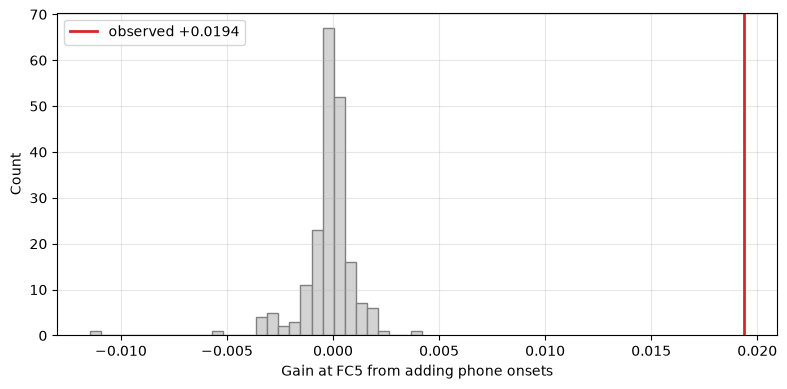

In [9]:
N_PERM = 200
rng = np.random.default_rng(0)


def evaluate_quiet(features):
    Xtr = design(features, train_parts)
    Xva = design(features, val_parts)
    Xte = design(features, test_parts)
    G, C = Xtr @ Xtr.T, Xtr @ tr_eeg.T
    I = np.eye(Xtr.shape[0])
    val_r, test_r = [], []
    for al in alphas:
        w = np.linalg.inv(G + al * I) @ C
        pv, pt = Xva.T @ w, Xte.T @ w
        val_r.append([pearsonr(pv[:, c], va_eeg[c])[0] for c in range(63)])
        test_r.append([pearsonr(pt[:, c], te_eeg[c])[0] for c in range(63)])
    val_r, test_r = np.array(val_r), np.array(test_r)
    best = val_r.argmax(axis=0)
    return None, test_r[best, np.arange(63)]

def gain_for(ph_list, r_e):
    _, r_b = evaluate_quiet([envs, ph_list])
    return r_b - r_e

gain = r_both - r_env
print(f"gain from adding phone onsets   FC5 {gain[fc5]:+.4f}   mean {gain.mean():+.4f}   "
      f"channels improved {(gain > 0).sum()} of 63")

cache_file = os.path.join(
    CACHE, f"null_gain_n{N_PERM}_a{len(alphas)}_l{len(lags)}_s10_trim.npy")   # all 63 channels

if os.path.exists(cache_file) and not RECOMPUTE:
    null_gain = np.load(cache_file)
    print(f"loaded {len(null_gain)} permutations from cache")
else:
    _, r_e_null = evaluate_quiet([envs])
    null_gain = []
    for j in range(N_PERM):
        shuf = [np.roll(phs[i], rng.integers(10*FS, len(phs[i]) - 10*FS))
                for i in range(15)]
        null_gain.append(gain_for(shuf, r_e_null))
        if (j + 1) % 25 == 0:
            print(f"  {j+1}/{N_PERM}")
    null_gain = np.array(null_gain)              # (N_PERM, 63)
    np.save(cache_file, null_gain)
    print(f"computed and saved to {os.path.basename(cache_file)}")

for name, o, null in [("FC5", gain[fc5], null_gain[:, fc5]),
                      ("mean", gain.mean(), null_gain.mean(axis=1))]:
    p = ((null >= o).sum() + 1) / (N_PERM + 1)
    print(f"{name:>4}  observed {o:+.4f}   null mean {null.mean():+.4f}   "
          f"95th {np.percentile(null, 95):+.4f}   p = {p:.4f}")

plt.figure(figsize=(8, 4))
plt.hist(null_gain[:, fc5], bins=30, color='lightgrey', edgecolor='grey')
plt.axvline(gain[fc5], c='tab:red', lw=2, label=f'observed {gain[fc5]:+.4f}')
plt.xlabel('Gain at FC5 from adding phone onsets'); plt.ylabel('Count')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(FIG, "ph_gain_null.pdf"), bbox_inches="tight")

corrected threshold +0.0195: C3 +0.0230, FC3 +0.0307, FCz +0.0288
largest losses: [('FT10', -0.0102), ('T8', -0.0081), ('TP10', -0.0077)]


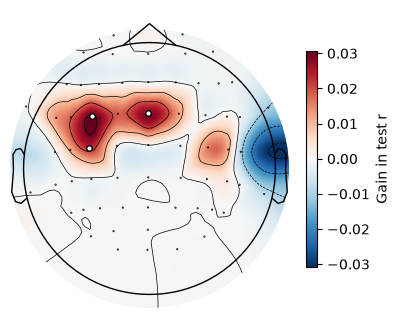

In [10]:
# where do phone onsets add to the envelope? ---
thr_g = np.percentile(null_gain.max(axis=1), 95)
sig_g = gain > thr_g
print(f"corrected threshold {thr_g:+.4f}: "
      + ", ".join(f"{ch_names[k]} {gain[k]:+.4f}" for k in np.flatnonzero(sig_g)))

vg = np.abs(gain).max()
fig, ax = plt.subplots(figsize=(4.5, 4))
im, _ = mne.viz.plot_topomap(gain, info, axes=ax, cmap='RdBu_r', vlim=(-vg, vg), mask=sig_g, show=False)
cbar = fig.colorbar(im, ax=ax, shrink=0.7)
cbar.set_label('Gain in test r')
plt.savefig(os.path.join(FIG, "ph_joint_gain.pdf"), bbox_inches="tight")
print("largest losses:", [(ch_names[k], round(float(gain[k]), 4)) for k in np.argsort(gain)[:3]])

In [11]:
strs = [zscore(s[:len(phs[i])]) for i, s in enumerate(str_on)]
unss = [zscore(u[:len(phs[i])]) for i, u in enumerate(uns_on)]
cons = [zscore(c[:len(phs[i])]) for i, c in enumerate(con_on)]
vows = [zscore(v[:len(phs[i])]) for i, v in enumerate(vow_on)]

_, r_all = evaluate([envs, phs],              "env + all phones")
_, r_vc  = evaluate([envs, vows, cons],       "env + vowel + cons")
_, r_svc = evaluate([envs, strs, unss, cons], "env + str + uns + cons")

print()
print(f"vowel/cons split over all phones   FC5 {r_vc[fc5]-r_all[fc5]:+.4f}   "
      f"mean {r_vc.mean()-r_all.mean():+.4f}   "
      f"channels improved {(r_vc > r_all).sum()} of 63")
print(f"stress split over vowel/cons       FC5 {r_svc[fc5]-r_vc[fc5]:+.4f}   "
      f"mean {r_svc.mean()-r_vc.mean():+.4f}   "
      f"channels improved {(r_svc > r_vc).sum()} of 63")


env + all phones       test mean 0.0438   FC5 0.1093   median alpha 1.0e+08
env + vowel + cons     test mean 0.0432   FC5 0.1082   median alpha 1.0e+08
env + str + uns + cons test mean 0.0425   FC5 0.1056   median alpha 1.0e+08

vowel/cons split over all phones   FC5 -0.0010   mean -0.0006   channels improved 42 of 63
stress split over vowel/cons       FC5 -0.0026   mean -0.0008   channels improved 21 of 63


n train 13634   vowel proportion 0.395
best lag 13 samples (104 ms)   balanced acc 0.5168
range across lags  0.4862 to 0.5168


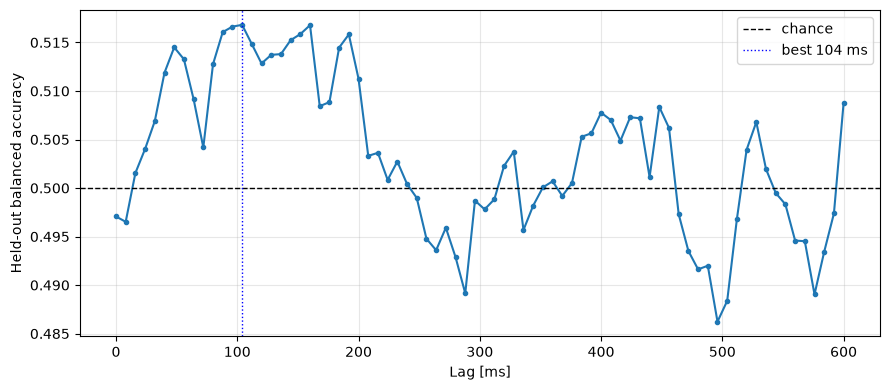

In [12]:
# vowel versus consonant onsets: single-lag classifier ---
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import balanced_accuracy_score

vc_lags = np.arange(0, 76)            # 0 to 600 ms at 125 Hz, as for stress

def vc_xy(parts, L):
    X, y = [], []
    for i in parts:
        e = eegs[i]                                    # (63, n)
        for arr, lab in [(vow_on[i], 1), (con_on[i], 0)]:
            for k in np.flatnonzero(arr):
                if k + L >= e.shape[1]:
                    continue
                X.append(e[:, k + L])                   # 63 values at one lag
                y.append(lab)
    return np.array(X), np.array(y)

bacc_vc = []
for L in vc_lags:
    Xs, ys = vc_xy(train_parts, L)
    Xv, yv = vc_xy(val_parts, L)
    sc = StandardScaler().fit(Xs)
    m = LogisticRegression(max_iter=2000, class_weight='balanced')
    m.fit(sc.transform(Xs), ys)
    bacc_vc.append(balanced_accuracy_score(yv, m.predict(sc.transform(Xv))))

bacc_vc = np.array(bacc_vc)
best_VC = int(vc_lags[bacc_vc.argmax()])
print(f"n train {len(ys)}   vowel proportion {ys.mean():.3f}")
print(f"best lag {best_VC} samples ({best_VC/FS*1000:.0f} ms)   balanced acc {bacc_vc.max():.4f}")
print(f"range across lags  {bacc_vc.min():.4f} to {bacc_vc.max():.4f}")

plt.figure(figsize=(9, 4))
plt.plot(vc_lags / FS * 1000, bacc_vc, marker='o', ms=3, c='tab:blue')
plt.axhline(0.5, c='k', ls='--', lw=1, label='chance')
plt.axvline(best_VC / FS * 1000, c='b', ls=':', lw=1, label=f'best {best_VC/FS*1000:.0f} ms')
plt.xlabel('Lag [ms]'); plt.ylabel('Held-out balanced accuracy')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(FIG, "ph_vc_scan.pdf"), bbox_inches="tight")

In [13]:
L = best_VC
Xs, ys = vc_xy(train_parts, L)
Xt, yt = vc_xy(test_parts, L)
sc = StandardScaler().fit(Xs)
m = LogisticRegression(max_iter=2000, class_weight='balanced').fit(sc.transform(Xs), ys)
b_test = balanced_accuracy_score(yt, m.predict(sc.transform(Xt)))

rng = np.random.default_rng(0)
shuf = np.array([balanced_accuracy_score(yt,
          LogisticRegression(max_iter=2000, class_weight='balanced')
          .fit(sc.transform(Xs), rng.permutation(ys)).predict(sc.transform(Xt)))
        for _ in range(200)])
p_vc = ((shuf >= b_test).sum() + 1) / (len(shuf) + 1)

print(f"lag {L} ({L/FS*1000:.0f} ms)   n test {len(yt)}")
print(f"test balanced accuracy {b_test:.4f}")
print(f"shuffled  mean {shuf.mean():.4f}   95th {np.percentile(shuf, 95):.4f}   p = {p_vc:.4f}")

lag 13 (104 ms)   n test 4040
test balanced accuracy 0.5281
shuffled  mean 0.4997   95th 0.5110   p = 0.0050


In [14]:
# does the vowel/consonant split help without the envelope? ---
_, r_vc_noenv = evaluate([vows, cons], "vowel + cons (no env)")
d_no  = r_vc_noenv - r_ph          # split gain, onsets only
d_env = r_vc - r_all               # split gain, with the envelope
print(f"\nsplit gain without envelope   FC5 {d_no[fc5]:+.4f}   mean {d_no.mean():+.4f}   "
      f"channels improved {(d_no > 0).sum()} of 63")
print(f"split gain with envelope      FC5 {d_env[fc5]:+.4f}   mean {d_env.mean():+.4f}   "
      f"channels improved {(d_env > 0).sum()} of 63")

vowel + cons (no env)  test mean 0.0240   FC5 0.1048   median alpha 1.0e+05

split gain without envelope   FC5 -0.0001   mean +0.0009   channels improved 37 of 63
split gain with envelope      FC5 -0.0010   mean -0.0006   channels improved 42 of 63


n train 5385   stressed proportion 0.576
best lag 42 samples (336 ms)   balanced acc 0.5534
range across lags  0.4848 to 0.5534


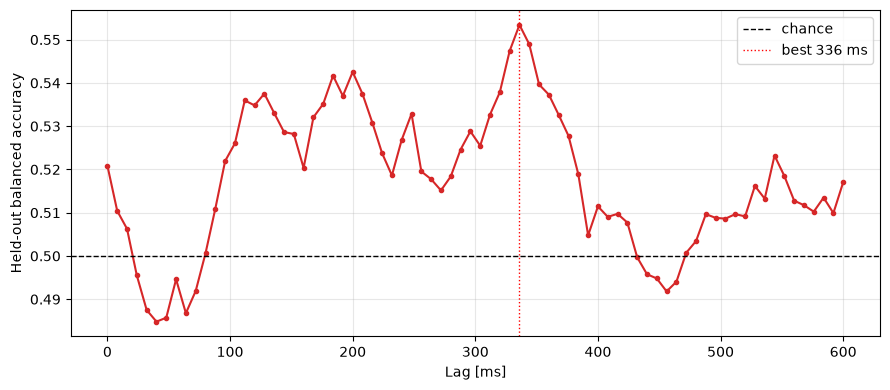

In [15]:

stress_lags = np.arange(0, 76)        # 0 to 600 ms at 125 Hz

def stress_xy(parts, L):
    X, y = [], []
    for i in parts:
        e = eegs[i]                                    # (63, n)
        for arr, lab in [(str_on[i], 1), (uns_on[i], 0)]:
            for k in np.flatnonzero(arr):
                if k + L >= e.shape[1]:
                    continue
                X.append(e[:, k + L])                   # 63 values at one lag
                y.append(lab)
    return np.array(X), np.array(y)

bacc_lag = []
for L in stress_lags:
    Xs, ys = stress_xy(train_parts, L)
    Xv, yv = stress_xy(val_parts, L)
    sc = StandardScaler().fit(Xs)
    m = LogisticRegression(max_iter=2000, class_weight='balanced')
    m.fit(sc.transform(Xs), ys)
    bacc_lag.append(balanced_accuracy_score(yv, m.predict(sc.transform(Xv))))

bacc_lag = np.array(bacc_lag)
best_SL = int(stress_lags[bacc_lag.argmax()])
print(f"n train {len(ys)}   stressed proportion {ys.mean():.3f}")
print(f"best lag {best_SL} samples ({best_SL/FS*1000:.0f} ms)   "
      f"balanced acc {bacc_lag.max():.4f}")
print(f"range across lags  {bacc_lag.min():.4f} to {bacc_lag.max():.4f}")

plt.figure(figsize=(9, 4))
plt.plot(stress_lags / FS * 1000, bacc_lag, marker='o', ms=3, c='tab:red')
plt.axhline(0.5, c='k', ls='--', lw=1, label='chance')
plt.axvline(best_SL / FS * 1000, c='r', ls=':', lw=1,
            label=f'best {best_SL/FS*1000:.0f} ms')
plt.xlabel('Lag [ms]'); plt.ylabel('Held-out balanced accuracy')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(FIG, "ph_stress_scan.pdf"), bbox_inches="tight")

In [16]:
L = best_SL
Xs, ys = stress_xy(train_parts, L)
Xt, yt = stress_xy(test_parts, L)
sc = StandardScaler().fit(Xs)
m = LogisticRegression(max_iter=2000, class_weight='balanced').fit(sc.transform(Xs), ys)
pred = m.predict(sc.transform(Xt))

print(f"lag {L} ({L/FS*1000:.0f} ms)   n test {len(yt)}")
print(f"test balanced accuracy {balanced_accuracy_score(yt, pred):.4f}")

rng = np.random.default_rng(0)
shuf = [balanced_accuracy_score(yt,
          LogisticRegression(max_iter=2000, class_weight='balanced')
          .fit(sc.transform(Xs), rng.permutation(ys)).predict(sc.transform(Xt)))
        for _ in range(200)]
b_str = balanced_accuracy_score(yt, pred)
p_str = ((np.array(shuf) >= b_str).sum() + 1) / (len(shuf) + 1)
print(f"shuffled  mean {np.mean(shuf):.4f}   95th {np.percentile(shuf, 95):.4f}   p = {p_str:.4f}")

lag 42 (336 ms)   n test 1618
test balanced accuracy 0.4998
shuffled  mean 0.5021   95th 0.5201   p = 0.5771


best lag 9 samples (72 ms)   r 0.0593


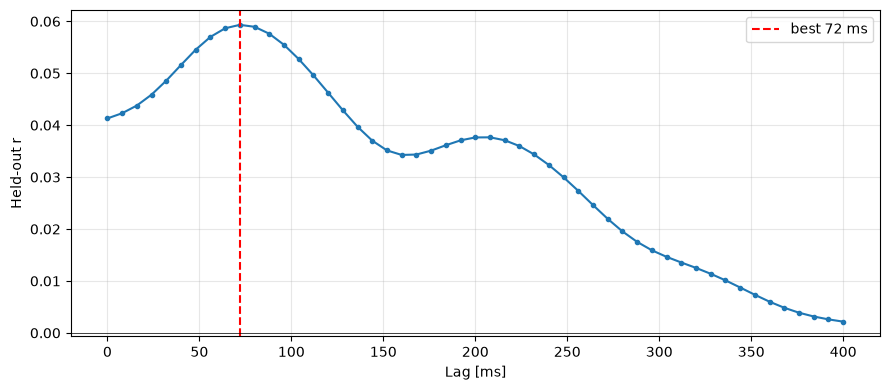

In [17]:
from sklearn.linear_model import LinearRegression

lag_scan = np.arange(0, 51)          # 0 to 400 ms at 125 Hz

def lag_xy(parts, L):
    Xs, ys = [], []
    for i in parts:
        e = eegs[i].T                # (n, 63)
        p = phs[i]                   # (n,)
        if L == 0:
            Xs.append(e); ys.append(p)
        else:
            Xs.append(e[L:]); ys.append(p[:-L])   # EEG[t+L] predicts onset[t]
    return np.vstack(Xs), np.concatenate(ys)

r_lag = []
for L in lag_scan:
    Xtr_l, ytr_l = lag_xy(train_parts, L)
    Xva_l, yva_l = lag_xy(val_parts, L)
    m = LinearRegression().fit(Xtr_l, ytr_l)
    r_lag.append(pearsonr(yva_l, m.predict(Xva_l))[0])

r_lag = np.array(r_lag)
best_L = int(lag_scan[r_lag.argmax()])
print(f"best lag {best_L} samples ({best_L/FS*1000:.0f} ms)   r {r_lag.max():.4f}")

plt.figure(figsize=(9, 4))
plt.plot(lag_scan / FS * 1000, r_lag, marker='o', ms=3)
plt.axvline(best_L / FS * 1000, c='r', ls='--',
            label=f'best {best_L/FS*1000:.0f} ms')
plt.axhline(0, c='k', lw=0.5)
plt.xlabel('Lag [ms]'); plt.ylabel('Held-out r')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(FIG, "ph_lag_scan.pdf"), bbox_inches="tight")

In [18]:
def lag_xy_t(target, parts, L):
    Xs, ys = [], []
    for i in parts:
        e, p = eegs[i].T, target[i]
        Xs.append(e[L:] if L else e); ys.append(p[:-L] if L else p)
    return np.vstack(Xs), np.concatenate(ys)

L = best_L
Xtr_l, ytr_l = lag_xy_t(phs, train_parts, L)
Xte_l, yte_l = lag_xy_t(phs, test_parts, L)
m = LinearRegression().fit(Xtr_l, ytr_l)
p_te = m.predict(Xte_l)
r_test = pearsonr(yte_l, p_te)[0]

# circular-shift null with the prediction fixed, as in notebook 02
rng_lag = np.random.default_rng(0)
parts_te = [lag_xy_t(phs, [i], L)[1] for i in test_parts]
null_r = np.empty(1000)
for k in range(1000):
    shifted = np.concatenate([np.roll(t, rng_lag.integers(10*FS, len(t) - 10*FS))
                              for t in parts_te])
    null_r[k] = pearsonr(shifted, p_te)[0]

p_lag = ((null_r >= r_test).sum() + 1) / (len(null_r) + 1)
print(f"lag {L} ({L/FS*1000:.0f} ms)   test r {r_test:.4f}")
print(f"null mean {null_r.mean():+.4f}   95th {np.percentile(null_r, 95):+.4f}   p = {p_lag:.4f}")

lag 9 (72 ms)   test r 0.0598
null mean +0.0001   95th +0.0080   p = 0.0010


loaded scan from cache
stressed-vowel samples in training: 3104 of 185387 (1.7%)
stressed    best lag 11 (88 ms)   balanced acc 0.5537
unstressed  best lag 12 (96 ms)   balanced acc 0.5485


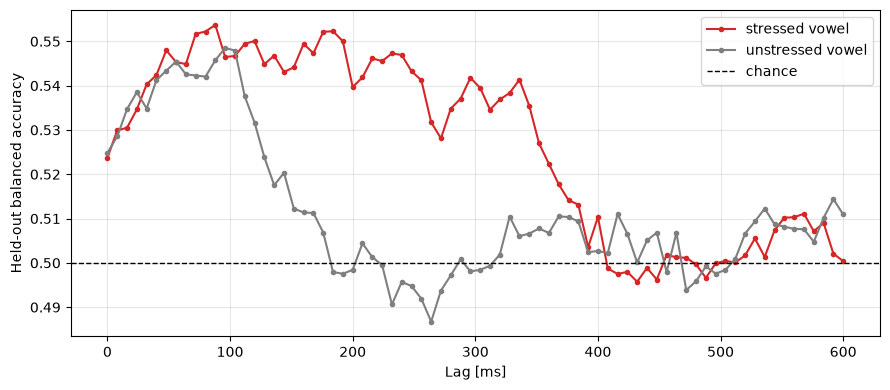

In [19]:

det_lags = np.arange(0, 76)            # 0 to 600 ms at 125 Hz

def det_xy(target, parts, L):
    Xs, ys = [], []
    for i in parts:
        e = eegs[i].T                  # (n, 63), already z-scored
        t = target[i][:e.shape[0]]     # 1 = target vowel onset, 0 = any other sample
        if L == 0:
            Xs.append(e); ys.append(t)
        else:
            Xs.append(e[L:]); ys.append(t[:-L])   # EEG[t+L] vs label at t
    return np.vstack(Xs), np.concatenate(ys).astype(int)

def scan(target):
    out = []
    for L in det_lags:
        Xs, ys = det_xy(target, train_parts, L)
        Xv, yv = det_xy(target, val_parts, L)
        m = LogisticRegression(max_iter=1000, class_weight='balanced').fit(Xs, ys)
        out.append(balanced_accuracy_score(yv, m.predict(Xv)))
    return np.array(out)

bacc_cache = os.path.join(CACHE, f"det_scan_l{len(det_lags)}.npz")

if os.path.exists(bacc_cache) and not RECOMPUTE:
    d = np.load(bacc_cache)
    bacc_str, bacc_uns = d["bacc_str"], d["bacc_uns"]
    print("loaded scan from cache")
else:
    bacc_str = scan(str_on)
    bacc_uns = scan(uns_on)
    np.savez(bacc_cache, bacc_str=bacc_str, bacc_uns=bacc_uns)
    print(f"computed and saved to {os.path.basename(bacc_cache)}")

best_DL = int(det_lags[bacc_str.argmax()])
_, ys = det_xy(str_on, train_parts, 0)
print(f"stressed-vowel samples in training: {ys.sum()} of {len(ys)} ({ys.mean()*100:.1f}%)")
print(f"stressed    best lag {best_DL} ({best_DL/FS*1000:.0f} ms)   "
      f"balanced acc {bacc_str.max():.4f}")
print(f"unstressed  best lag {int(det_lags[bacc_uns.argmax()])} "
      f"({det_lags[bacc_uns.argmax()]/FS*1000:.0f} ms)   "
      f"balanced acc {bacc_uns.max():.4f}")

plt.figure(figsize=(9, 4))
plt.plot(det_lags/FS*1000, bacc_str, marker='o', ms=3, c='tab:red',  label='stressed vowel')
plt.plot(det_lags/FS*1000, bacc_uns, marker='o', ms=3, c='tab:grey', label='unstressed vowel')
plt.axhline(0.5, c='k', ls='--', lw=1, label='chance')
plt.xlabel('Lag [ms]'); plt.ylabel('Held-out balanced accuracy')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(FIG, "ph_detection_scan.pdf"), bbox_inches="tight")

loaded 100 permutations from cache

vowels  train 5385   test 1618
stressed 0.5336   unstressed 0.5010   gap +0.0326
null gap  mean +0.0024   95th +0.0162
p = 0.0099


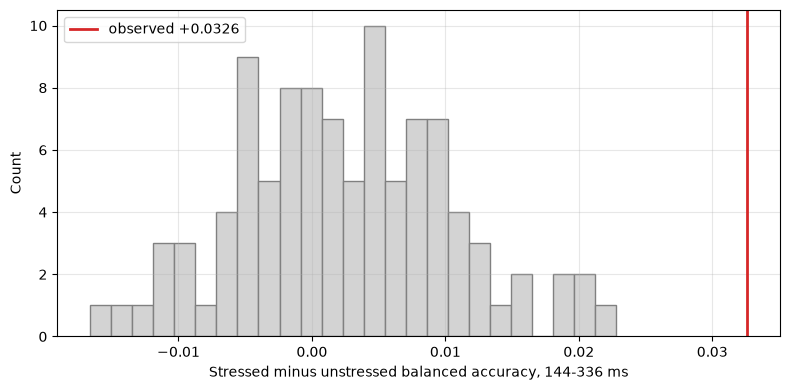

In [20]:
win = (det_lags >= int(0.150*FS)) & (det_lags <= int(0.350*FS))
win_lags = det_lags[win]
N_NEG_TR, N_NEG_TE, N_PERM_GAP = 20000, 30000, 100
WIN_LAGS = win_lags[::2]                 # every 2nd lag in 150-350 ms, 13 lags
Lmax = int(WIN_LAGS.max())
rng_gap = np.random.default_rng(1)

def gather(parts, n_neg):
    """All vowel onsets (usable at every window lag) + a fixed random sample of non-vowel samples."""
    vp, npos, labs = [], [], []
    for i in parts:
        n = eegs[i].shape[1]
        v = vow_on[i][:n - Lmax]
        p = np.flatnonzero(v)
        vp.append((i, p))
        npos.append((i, np.flatnonzero(v == 0)))
        labs.append(str_on[i][p].astype(int))
    sizes = np.array([len(k) for _, k in npos])
    offs = np.concatenate([[0], np.cumsum(sizes)])
    pick = np.sort(rng_gap.choice(offs[-1], n_neg, replace=False))
    nsel = [(i, k[pick[(pick >= offs[j]) & (pick < offs[j+1])] - offs[j]])
            for j, (i, k) in enumerate(npos)]
    X = {}
    for L in WIN_LAGS:
        rows = [eegs[i][:, k + L].T for i, k in vp] + [eegs[i][:, k + L].T for i, k in nsel]
        X[L] = np.vstack(rows).astype(np.float32)
    return X, np.concatenate(labs), n_neg

Xtr_w, s_tr, nn_tr = gather(train_parts, N_NEG_TR)
Xte_w, s_te, nn_te = gather(test_parts,  N_NEG_TE)
zeros_tr, zeros_te = np.zeros(nn_tr, int), np.zeros(nn_te, int)

def window_scores(s_tr, s_te):
    bs, bu = [], []
    for L in WIN_LAGS:
        for lab_tr, lab_te, out in [(s_tr, s_te, bs), (1 - s_tr, 1 - s_te, bu)]:
            y  = np.concatenate([lab_tr, zeros_tr])
            yt = np.concatenate([lab_te, zeros_te])
            m = LogisticRegression(max_iter=1000, class_weight='balanced').fit(Xtr_w[L], y)
            out.append(balanced_accuracy_score(yt, m.predict(Xte_w[L])))
    return np.mean(bs), np.mean(bu)

obs_s, obs_u = window_scores(s_tr, s_te)
obs_gap = obs_s - obs_u

gap_cache = os.path.join(
    CACHE, f"null_gap_n{N_PERM_GAP}_L{len(WIN_LAGS)}_ntr{N_NEG_TR}_nte{N_NEG_TE}.npy")

if os.path.exists(gap_cache) and not RECOMPUTE:
    null_gap = np.load(gap_cache)
    print(f"loaded {len(null_gap)} permutations from cache")
else:
    null_gap = []
    for j in range(N_PERM_GAP):
        g_s, g_u = window_scores(rng_gap.permutation(s_tr), rng_gap.permutation(s_te))
        null_gap.append(g_s - g_u)
        if (j + 1) % 20 == 0:
            print(f"  {j+1}/{N_PERM_GAP}")
    null_gap = np.array(null_gap)
    np.save(gap_cache, null_gap)
    print(f"computed and saved to {os.path.basename(gap_cache)}")

p_gap = ((null_gap >= obs_gap).sum() + 1) / (N_PERM_GAP + 1)

print(f"\nvowels  train {len(s_tr)}   test {len(s_te)}")
print(f"stressed {obs_s:.4f}   unstressed {obs_u:.4f}   gap {obs_gap:+.4f}")
print(f"null gap  mean {null_gap.mean():+.4f}   95th {np.percentile(null_gap, 95):+.4f}")
print(f"p = {p_gap:.4f}")

plt.figure(figsize=(8, 4))
plt.hist(null_gap, bins=25, color='lightgrey', edgecolor='grey')
plt.axvline(obs_gap, c='tab:red', lw=2, label=f'observed {obs_gap:+.4f}')
plt.xlabel('Stressed minus unstressed balanced accuracy, 144-336 ms')
plt.ylabel('Count'); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(FIG, "ph_detection_null.pdf"), bbox_inches="tight")